# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [5]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [6]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [7]:
path = '../../../data/clean/Campo 20 puntos'

## Datos de entrenamiento

### Datos

In [8]:
campvectrain = np.load(path + '/campvectrain.npy')

In [9]:
np.shape(campvectrain)

(7000, 2, 20, 20)

### Coeficientes

In [10]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [11]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [12]:
campvectest = np.load(path + '/campvectest.npy')

In [13]:
np.shape(campvectest)

(1000, 2, 20, 20)

### Coeficientes

In [14]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [15]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [16]:
campvecval = np.load(path + '/campvecval.npy')

In [17]:
np.shape(campvecval)

(2000, 2, 20, 20)

### Coeficienes

In [18]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [19]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [20]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [21]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 20, 20), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [22]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creamos función de costo

In [23]:
def custom_loss(y_true, y_pred):
    campvec = []
    # constantes
    a1 = tf.cast(y_true[:, 0], tf.float64)
    #tf.print(a1)
    a1 = tf.reshape(a1, shape=(-1, 1, 1))

    a2 = tf.cast(y_true[:, 1], tf.float64)
    a2 = tf.reshape(a2, shape=(-1, 1, 1))
    
    b1 = tf.cast(y_true[:, 2], tf.float64)
    b1 = tf.reshape(b1,shape = (-1,1,1))
    
    b2 = tf.cast(y_true[:, 3], tf.float64)
    b2 = tf.reshape(b2,shape = (-1,1,1))

    d1 = tf.cast(y_true[:, 4], tf.float64)
    d1 = tf.reshape(d1, shape=(-1, 1, 1))

    d2 = tf.cast(y_true[:, 5], tf.float64)
    d2 = tf.reshape(d2, shape=(-1, 1, 1))

    n = tf.cast(y_true[:, 6], tf.float64)
    n = tf.reshape(n, shape=(-1, 1, 1))

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        X = tf.cast(X, tf.float64)
        X = tf.reshape(X, shape=(1, 20,20))
        Y = y[1]
        Y = tf.cast(Y, tf.float64)
        Y = tf.reshape(Y, shape=(1, 20,20))
        
        # definimos cada ODE
        dX_dt = tf.divide(a1,(1 + tf.math.pow(Y, n)+1e-5)) - tf.multiply(d1,X) + b1
        dY_dt = tf.divide(a2,(1 + tf.math.pow(X, n)+1e-7)) - tf.multiply(d2,Y) + b2
        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 20
    y_range_neg = 0
    y_range_pos = 20
    y1 = tf.linspace(x_range_neg, x_range_pos, 20)
    y2 = tf.linspace(y_range_neg, y_range_pos, 20)
    Y1, Y2 = tf.meshgrid(y1, y2)
    t = 0
    u, v = tf.zeros(Y1.shape), tf.zeros(Y2.shape)
    u, v = f(t, [Y1, Y2])
    #M = tf.sqrt(tf.square(u) + tf.square(v))
    #u /= M
    #v /= M
# ----------------------------------------------------------------------------
    campvec2 = []
    # constantes
    a12 = tf.cast(y_pred[:, 0], tf.float64)
    a12 = tf.reshape(a12, shape=(-1, 1, 1))

    a22 = tf.cast(y_pred[:, 1], tf.float64)
    a22 = tf.reshape(a22, shape=(-1, 1, 1))
    
    b12 = tf.cast(y_pred[:, 2], tf.float64)
    b12 = tf.reshape(b12,shape = (-1,1,1))
    
    b22 = tf.cast(y_pred[:, 3], tf.float64)
    b22 = tf.reshape(b22,shape = (-1,1,1))

    d12 = tf.cast(y_pred[:, 4], tf.float64)
    d12 = tf.reshape(d12, shape=(-1, 1, 1))

    d22 = tf.cast(y_pred[:, 5], tf.float64)
    d22 = tf.reshape(d22, shape=(-1, 1, 1))

    n2 = tf.cast(y_pred[:, 6], tf.float64)
    n2 = tf.reshape(n2, shape=(-1, 1, 1))
    
    def f2(t2, ye2):

        # asignar a cada ODE a un elemento de vector
        X2 = ye2[0]
        X2 = tf.cast(X2, tf.float64)
        X2 = tf.reshape(X2, shape=(1, 20,20))
        Y2 = ye2[1]
        Y2 = tf.cast(Y2, tf.float64)
        Y2 = tf.reshape(Y2, shape=(1, 20,20))

        # definimos cada ODE
        dX2_dt = tf.divide(a12,(1 + tf.math.pow(Y2, n2)+1e-8)) - tf.multiply(d12,X2) + b12
        dY2_dt = tf.divide(a22,(1 + tf.math.pow(X2, n2)+1e-8)) - tf.multiply(d22,Y2) + b22
        return [dX2_dt, dY2_dt]

    y12 = tf.linspace(x_range_neg, x_range_pos, 20)
    y22 = tf.linspace(y_range_neg, y_range_pos, 20)
    Y12, Y22 = tf.meshgrid(y12, y22)
    u2, v2 = tf.zeros(Y12.shape), tf.zeros(Y22.shape)
    u2, v2 = f2(t, [Y12, Y22])
    #M2 = tf.sqrt(tf.square(u2) + tf.square(v2))
    #u2 /= M2
    #v2 /= M2
    campvecx = tf.abs(tf.subtract(u,u2))
    campvecy = tf.abs(tf.subtract(v,v2))
    campvec_magnitude = tf.add(campvecx,campvecy)
    loss = tf.reduce_mean(campvec_magnitude)
    #tf.print(y_pred)
    return loss

# Creación del modelo

In [31]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [24]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [25]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [26]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [29]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.000001  # Updated final learning rate
    start_decay_epoch = 200
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [34]:
def scheduler(epoch, lr):
  if epoch < 500:
    return lr
  else:
    return 1e-3 * 0.99 ** epoch

In [36]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2
import optuna

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)

def objective(trial):
    model = Sequential()
    
    model.add(Flatten(input_shape=(2, 20, 20)))  # Tus dimensiones de entrada
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 8)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))  # Asumiendo que tienes una función 'custom_activation'
    
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
  
    model.compile(optimizer=optimizer, loss= custom_loss, metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=300)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

[I 2023-09-22 16:06:40,933] A new study created in memory with name: no-name-cd7375da-aa55-4f07-8512-fbe6dc1c3950


Epoch 1/20
70/70 [==============================] - 2s 9ms/step - loss: 40.8963 - a_1: 2.9015 - a_2: 3.1064 - b_1: 2.8305 - b_2: 2.9775 - d_1: 2.0957 - d_2: 1.8836 - n: 3.1073 - mean_metric: 0.6250 - val_loss: 26.0457 - val_a_1: 2.8477 - val_a_2: 3.0022 - val_b_1: 2.6807 - val_b_2: 2.7418 - val_d_1: 1.3548 - val_d_2: 1.2267 - val_n: 3.2026 - val_mean_metric: 0.5585 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 0s 4ms/step - loss: 32.1183 - a_1: 3.0197 - a_2: 3.1377 - b_1: 2.8113 - b_2: 2.9125 - d_1: 1.6059 - d_2: 1.5410 - n: 3.3619 - mean_metric: 0.6080 - val_loss: 25.9336 - val_a_1: 2.8886 - val_a_2: 3.0159 - val_b_1: 2.6770 - val_b_2: 2.6652 - val_d_1: 1.2061 - val_d_2: 1.3561 - val_n: 3.2755 - val_mean_metric: 0.5594 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 0s 4ms/step - loss: 32.1808 - a_1: 3.0054 - a_2: 3.1756 - b_1: 2.8642 - b_2: 2.9132 - d_1: 1.5854 - d_2: 1.5796 - n: 3.4391 - mean_metric: 0.6137 - val_loss: 23.8853 - val_a_1: 2.9000 - 

[I 2023-09-22 16:06:48,238] Trial 0 finished with value: 0.5211998224258423 and parameters: {'n_dense_layers': 5, 'num_units_1': 116, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 32, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'glorot_uniform', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': True, 'dropout_rate_after_dense_2': 0.20732448498999367, 'num_units_3': 95, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'glorot_uniform', 'dense_kernel_regularizer_3': 'l1', 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.12773126819531633, 'num_units_4': 26, 'dense_activation_4': 'tanh', 'dense_kernel_initializer_4': 'random_normal', 'dense_kernel_regularizer_4': 'l1', 'add_dropout_after_dense_4': True, 'dropout_rate_after_dense_4': 0.3278925433135311, 'num_units_5': 56, 'dense_activation_5': 'relu', 'dense_kernel

Epoch 1/20
70/70 [==============================] - 1s 8ms/step - loss: 35.4501 - a_1: 2.7918 - a_2: 2.8306 - b_1: 2.6967 - b_2: 2.7636 - d_1: 1.6332 - d_2: 1.7334 - n: 1.8639 - mean_metric: 0.5395 - val_loss: 24.1401 - val_a_1: 2.9062 - val_a_2: 2.8665 - val_b_1: 2.6173 - val_b_2: 2.5637 - val_d_1: 1.1848 - val_d_2: 1.1377 - val_n: 1.5478 - val_mean_metric: 0.4854 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 0s 4ms/step - loss: 26.9139 - a_1: 2.8676 - a_2: 2.9201 - b_1: 2.6419 - b_2: 2.6901 - d_1: 1.2880 - d_2: 1.2904 - n: 1.5868 - mean_metric: 0.5054 - val_loss: 22.4647 - val_a_1: 2.9053 - val_a_2: 2.9199 - val_b_1: 2.6206 - val_b_2: 2.5663 - val_d_1: 1.0884 - val_d_2: 1.0696 - val_n: 1.5181 - val_mean_metric: 0.4810 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 0s 3ms/step - loss: 25.2008 - a_1: 2.8722 - a_2: 2.8857 - b_1: 2.6472 - b_2: 2.6797 - d_1: 1.2117 - d_2: 1.2045 - n: 1.5726 - mean_metric: 0.4984 - val_loss: 23.0149 - val_a_1: 2.9021 - 

[I 2023-09-22 16:06:54,502] Trial 1 finished with value: 0.4831668734550476 and parameters: {'n_dense_layers': 4, 'num_units_1': 77, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 74, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'HeNormal', 'dense_kernel_regularizer_2': 'l1', 'add_dropout_after_dense_2': True, 'dropout_rate_after_dense_2': 0.47000957677683874, 'num_units_3': 76, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'random_normal', 'dense_kernel_regularizer_3': 'l1', 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.44977230133024915, 'num_units_4': 115, 'dense_activation_4': 'sigmoid', 'dense_kernel_initializer_4': 'glorot_uniform', 'dense_kernel_regularizer_4': 'l1', 'add_dropout_after_dense_4': False}. Best is trial 1 with value: 0.4831668734550476.


Epoch 1/20
70/70 [==============================] - 2s 8ms/step - loss: 35.1460 - a_1: 2.9764 - a_2: 2.9627 - b_1: 2.9889 - b_2: 2.9763 - d_1: 1.7719 - d_2: 1.7335 - n: 2.4987 - mean_metric: 0.5921 - val_loss: 23.3355 - val_a_1: 2.9075 - val_a_2: 2.9054 - val_b_1: 2.9048 - val_b_2: 2.8178 - val_d_1: 1.2599 - val_d_2: 1.1304 - val_n: 2.5433 - val_mean_metric: 0.5393 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 0s 3ms/step - loss: 30.0015 - a_1: 2.9984 - a_2: 2.9226 - b_1: 2.9260 - b_2: 3.0685 - d_1: 1.5257 - d_2: 1.4969 - n: 2.7936 - mean_metric: 0.5863 - val_loss: 23.8347 - val_a_1: 2.9168 - val_a_2: 2.9100 - val_b_1: 2.7587 - val_b_2: 2.9966 - val_d_1: 1.1774 - val_d_2: 1.2824 - val_n: 2.7184 - val_mean_metric: 0.5489 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 0s 3ms/step - loss: 28.5120 - a_1: 3.0160 - a_2: 2.8883 - b_1: 2.8408 - b_2: 3.0993 - d_1: 1.4375 - d_2: 1.4430 - n: 2.8195 - mean_metric: 0.5801 - val_loss: 22.8013 - val_a_1: 2.8960 - 

... (592 outputs left out)

[I 2023-09-22 17:25:15,660] Trial 298 finished with value: 0.3813532590866089 and parameters: {'n_dense_layers': 2, 'num_units_1': 49, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 126, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False}. Best is trial 298 with value: 0.3813532590866089.


Epoch 1/20
70/70 [==============================] - 2s 16ms/step - loss: 29.4365 - a_1: 2.7333 - a_2: 2.8908 - b_1: 2.6618 - b_2: 2.7315 - d_1: 1.5647 - d_2: 1.4569 - n: 4.5651 - mean_metric: 0.6152 - val_loss: 20.6161 - val_a_1: 2.8266 - val_a_2: 2.8710 - val_b_1: 2.6212 - val_b_2: 2.5800 - val_d_1: 1.1189 - val_d_2: 1.0848 - val_n: 3.8151 - val_mean_metric: 0.5540 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 12ms/step - loss: 19.6455 - a_1: 2.8109 - a_2: 2.8558 - b_1: 2.6172 - b_2: 2.6519 - d_1: 1.0687 - d_2: 1.0499 - n: 2.2856 - mean_metric: 0.5073 - val_loss: 19.1726 - val_a_1: 2.8311 - val_a_2: 2.8110 - val_b_1: 2.5906 - val_b_2: 2.5497 - val_d_1: 1.0660 - val_d_2: 1.0110 - val_n: 1.8225 - val_mean_metric: 0.4807 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 11ms/step - loss: 19.6438 - a_1: 2.8771 - a_2: 2.8333 - b_1: 2.5896 - b_2: 2.6554 - d_1: 1.0651 - d_2: 1.0356 - n: 1.8055 - mean_metric: 0.4913 - val_loss: 19.1686 - val_a_1: 2.8606

[I 2023-09-22 17:25:33,024] Trial 299 finished with value: 0.4702117443084717 and parameters: {'n_dense_layers': 2, 'num_units_1': 60, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': False, 'num_units_2': 126, 'dense_activation_2': 'sigmoid', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False}. Best is trial 298 with value: 0.3813532590866089.


Número de trials finalizados: 300
Mejor trial:
  Valor: 0.3813532590866089
  Parámetros: 
    n_dense_layers: 2
    num_units_1: 49
    dense_activation_1: relu
    dense_kernel_initializer_1: glorot_uniform
    dense_kernel_regularizer_1: l2
    add_dropout_after_dense_1: False
    num_units_2: 126
    dense_activation_2: sigmoid
    dense_kernel_initializer_2: random_normal
    dense_kernel_regularizer_2: l2
    add_dropout_after_dense_2: False


In [22]:
model = Sequential()
model.add(Flatten(input_shape=(2, 20, 20)))
model.add(BatchNormalization())
model.add(Dense(100, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dense(100, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(100, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dense(50, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(BatchNormalization())
model.add(Dense(50, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.2))
model.add(Dense(50, activation='tanh', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dense(7))

In [43]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2

# Initialize the model
model = Sequential()

model.add(Flatten(input_shape=(2,20,20)))
# Add Dense Layers
# Dense Layer 1
model.add(Dense(49, activation='relu', kernel_initializer='glorot_uniform', kernel_regularizer=l2(0.001)))

# Dense Layer 2
model.add(Dense(126, activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))

# Show the model architecture
model.add(Dense(7, activation= custom_activation))

model.summary()


Model: "sequential_306"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_306 (Flatten)       (None, 800)               0         
                                                                 
 dense_1164 (Dense)          (None, 49)                39249     
                                                                 
 dense_1165 (Dense)          (None, 126)               6300      
                                                                 
 dense_1166 (Dense)          (None, 7)                 889       
                                                                 
Total params: 46,438
Trainable params: 46,438
Non-trainable params: 0
_________________________________________________________________


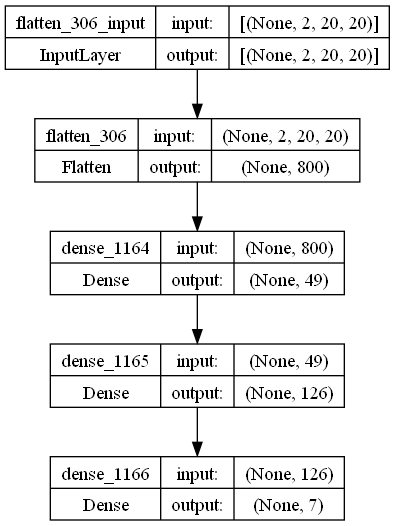

In [44]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [45]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [46]:
model.compile(optimizer=optimizer,
              loss= custom_loss,
              metrics=metrics)

In [47]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.0001  # Updated final learning rate
    start_decay_epoch = 150
    end_decay_epoch = 350
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr
    
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

In [48]:
val_epochs = 350

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/350
70/70 [==============================] - 2s 16ms/step - loss: 19.9779 - a_1: 2.9264 - a_2: 3.0855 - b_1: 2.7666 - b_2: 2.9188 - d_1: 1.0518 - d_2: 1.0775 - n: 1.6716 - mean_metric: 0.5126 - val_loss: 16.6155 - val_a_1: 2.8327 - val_a_2: 2.8804 - val_b_1: 2.5842 - val_b_2: 2.7515 - val_d_1: 0.9084 - val_d_2: 0.9189 - val_n: 1.7721 - val_mean_metric: 0.4796 - lr: 0.0010
Epoch 2/350
70/70 [==============================] - 1s 12ms/step - loss: 15.8010 - a_1: 2.7530 - a_2: 2.9041 - b_1: 2.6372 - b_2: 2.6711 - d_1: 0.8574 - d_2: 0.8418 - n: 1.9103 - mean_metric: 0.4819 - val_loss: 15.5327 - val_a_1: 2.9544 - val_a_2: 2.9641 - val_b_1: 2.5594 - val_b_2: 2.5018 - val_d_1: 0.8379 - val_d_2: 0.8362 - val_n: 2.0121 - val_mean_metric: 0.4801 - lr: 0.0010
Epoch 3/350
70/70 [==============================] - 1s 12ms/step - loss: 14.5297 - a_1: 2.7095 - a_2: 2.9637 - b_1: 2.5727 - b_2: 2.4477 - d_1: 0.7671 - d_2: 0.7952 - n: 2.0101 - mean_metric: 0.4715 - val_loss: 13.4910 - val_a_1: 2.7

70/70 [==============================] - 1s 12ms/step - loss: 4.8647 - a_1: 2.5997 - a_2: 2.7537 - b_1: 1.6455 - b_2: 1.8205 - d_1: 0.2458 - d_2: 0.2411 - n: 2.0448 - mean_metric: 0.3752 - val_loss: 4.6425 - val_a_1: 2.6475 - val_a_2: 2.7136 - val_b_1: 1.7629 - val_b_2: 1.5890 - val_d_1: 0.2268 - val_d_2: 0.2439 - val_n: 2.0667 - val_mean_metric: 0.3683 - lr: 0.0010
Epoch 44/350
70/70 [==============================] - 1s 12ms/step - loss: 4.8540 - a_1: 2.6017 - a_2: 2.7465 - b_1: 1.6369 - b_2: 1.7490 - d_1: 0.2547 - d_2: 0.2328 - n: 2.0399 - mean_metric: 0.3721 - val_loss: 4.6735 - val_a_1: 2.6130 - val_a_2: 2.7225 - val_b_1: 1.6307 - val_b_2: 2.0495 - val_d_1: 0.2190 - val_d_2: 0.2734 - val_n: 1.9614 - val_mean_metric: 0.3754 - lr: 0.0010
Epoch 45/350
70/70 [==============================] - 1s 12ms/step - loss: 5.0000 - a_1: 2.5871 - a_2: 2.7531 - b_1: 1.6004 - b_2: 1.7753 - d_1: 0.2520 - d_2: 0.2487 - n: 2.0307 - mean_metric: 0.3717 - val_loss: 4.6634 - val_a_1: 2.6174 - val_a_2: 2

70/70 [==============================] - 1s 12ms/step - loss: 4.3224 - a_1: 2.4391 - a_2: 2.5943 - b_1: 1.3398 - b_2: 1.4430 - d_1: 0.2194 - d_2: 0.2131 - n: 1.8735 - mean_metric: 0.3345 - val_loss: 4.7097 - val_a_1: 2.4653 - val_a_2: 2.5529 - val_b_1: 1.1752 - val_b_2: 1.3301 - val_d_1: 0.2113 - val_d_2: 0.2466 - val_n: 1.9408 - val_mean_metric: 0.3248 - lr: 0.0010
Epoch 86/350
70/70 [==============================] - 1s 12ms/step - loss: 4.8133 - a_1: 2.4479 - a_2: 2.6224 - b_1: 1.4377 - b_2: 1.5536 - d_1: 0.2522 - d_2: 0.2370 - n: 1.8631 - mean_metric: 0.3442 - val_loss: 4.5612 - val_a_1: 2.4554 - val_a_2: 2.5634 - val_b_1: 1.2629 - val_b_2: 1.4552 - val_d_1: 0.2132 - val_d_2: 0.2481 - val_n: 1.8514 - val_mean_metric: 0.3290 - lr: 0.0010
Epoch 87/350
70/70 [==============================] - 1s 12ms/step - loss: 4.7029 - a_1: 2.4343 - a_2: 2.6024 - b_1: 1.4303 - b_2: 1.4874 - d_1: 0.2379 - d_2: 0.2347 - n: 1.8663 - mean_metric: 0.3401 - val_loss: 4.5792 - val_a_1: 2.4600 - val_a_2: 2

70/70 [==============================] - 1s 12ms/step - loss: 4.2125 - a_1: 2.3744 - a_2: 2.5207 - b_1: 1.2360 - b_2: 1.3633 - d_1: 0.2128 - d_2: 0.2130 - n: 1.8135 - mean_metric: 0.3217 - val_loss: 3.7886 - val_a_1: 2.4018 - val_a_2: 2.4863 - val_b_1: 1.1953 - val_b_2: 1.3771 - val_d_1: 0.2008 - val_d_2: 0.1738 - val_n: 1.7624 - val_mean_metric: 0.3142 - lr: 0.0010
Epoch 128/350
70/70 [==============================] - 1s 12ms/step - loss: 4.5868 - a_1: 2.3930 - a_2: 2.5266 - b_1: 1.2048 - b_2: 1.2991 - d_1: 0.2297 - d_2: 0.2283 - n: 1.8047 - mean_metric: 0.3200 - val_loss: 4.3514 - val_a_1: 2.3895 - val_a_2: 2.5033 - val_b_1: 1.1702 - val_b_2: 1.6114 - val_d_1: 0.2110 - val_d_2: 0.1825 - val_n: 1.7183 - val_mean_metric: 0.3203 - lr: 0.0010
Epoch 129/350
70/70 [==============================] - 1s 12ms/step - loss: 4.4217 - a_1: 2.3533 - a_2: 2.4997 - b_1: 1.2133 - b_2: 1.3215 - d_1: 0.2194 - d_2: 0.2250 - n: 1.7886 - mean_metric: 0.3179 - val_loss: 3.7912 - val_a_1: 2.3357 - val_a_2:

70/70 [==============================] - 1s 12ms/step - loss: 4.2672 - a_1: 2.4536 - a_2: 2.5736 - b_1: 1.1738 - b_2: 1.2637 - d_1: 0.2156 - d_2: 0.2160 - n: 1.7483 - mean_metric: 0.3187 - val_loss: 3.8327 - val_a_1: 2.4103 - val_a_2: 2.4796 - val_b_1: 1.0434 - val_b_2: 1.4344 - val_d_1: 0.1990 - val_d_2: 0.1856 - val_n: 1.6527 - val_mean_metric: 0.3079 - lr: 9.1900e-04
Epoch 170/350
70/70 [==============================] - 1s 12ms/step - loss: 4.1680 - a_1: 2.3695 - a_2: 2.4817 - b_1: 1.0961 - b_2: 1.2798 - d_1: 0.2067 - d_2: 0.2125 - n: 1.7481 - mean_metric: 0.3105 - val_loss: 3.8958 - val_a_1: 2.4176 - val_a_2: 2.4792 - val_b_1: 1.1956 - val_b_2: 1.4265 - val_d_1: 0.1773 - val_d_2: 0.1909 - val_n: 1.6701 - val_mean_metric: 0.3128 - lr: 9.1450e-04
Epoch 171/350
70/70 [==============================] - 1s 12ms/step - loss: 4.6157 - a_1: 2.3959 - a_2: 2.5122 - b_1: 1.2074 - b_2: 1.2889 - d_1: 0.2317 - d_2: 0.2353 - n: 1.7265 - mean_metric: 0.3171 - val_loss: 3.9558 - val_a_1: 2.3907 - 

70/70 [==============================] - 1s 12ms/step - loss: 3.7248 - a_1: 2.3681 - a_2: 2.4774 - b_1: 1.1263 - b_2: 1.2430 - d_1: 0.1822 - d_2: 0.1954 - n: 1.7558 - mean_metric: 0.3090 - val_loss: 3.3429 - val_a_1: 2.3835 - val_a_2: 2.4627 - val_b_1: 1.0762 - val_b_2: 1.3594 - val_d_1: 0.1557 - val_d_2: 0.1749 - val_n: 1.5854 - val_mean_metric: 0.3011 - lr: 7.3000e-04
Epoch 212/350
70/70 [==============================] - 1s 12ms/step - loss: 3.5052 - a_1: 2.3815 - a_2: 2.4600 - b_1: 1.1073 - b_2: 1.1878 - d_1: 0.1751 - d_2: 0.1783 - n: 1.7479 - mean_metric: 0.3053 - val_loss: 3.4513 - val_a_1: 2.3816 - val_a_2: 2.4546 - val_b_1: 1.0428 - val_b_2: 1.1992 - val_d_1: 0.1631 - val_d_2: 0.1945 - val_n: 1.6944 - val_mean_metric: 0.2989 - lr: 7.2550e-04
Epoch 213/350
70/70 [==============================] - 1s 12ms/step - loss: 3.5898 - a_1: 2.3630 - a_2: 2.4535 - b_1: 1.0839 - b_2: 1.1957 - d_1: 0.1789 - d_2: 0.1855 - n: 1.7566 - mean_metric: 0.3046 - val_loss: 3.3258 - val_a_1: 2.2807 - 

70/70 [==============================] - 1s 12ms/step - loss: 3.0660 - a_1: 2.3589 - a_2: 2.4152 - b_1: 1.0496 - b_2: 1.1301 - d_1: 0.1555 - d_2: 0.1571 - n: 1.7609 - mean_metric: 0.2983 - val_loss: 3.9261 - val_a_1: 2.3407 - val_a_2: 2.3764 - val_b_1: 0.9306 - val_b_2: 1.1276 - val_d_1: 0.1867 - val_d_2: 0.2113 - val_n: 1.7628 - val_mean_metric: 0.2925 - lr: 5.4100e-04
Epoch 254/350
70/70 [==============================] - 1s 12ms/step - loss: 3.1858 - a_1: 2.3580 - a_2: 2.4079 - b_1: 1.0601 - b_2: 1.1329 - d_1: 0.1603 - d_2: 0.1627 - n: 1.7655 - mean_metric: 0.2990 - val_loss: 3.1132 - val_a_1: 2.5115 - val_a_2: 2.4399 - val_b_1: 1.1238 - val_b_2: 1.0882 - val_d_1: 0.1673 - val_d_2: 0.1447 - val_n: 1.8411 - val_mean_metric: 0.3049 - lr: 5.3650e-04
Epoch 255/350
70/70 [==============================] - 1s 12ms/step - loss: 3.3213 - a_1: 2.3545 - a_2: 2.3963 - b_1: 1.1135 - b_2: 1.1230 - d_1: 0.1665 - d_2: 0.1691 - n: 1.7596 - mean_metric: 0.3002 - val_loss: 2.8693 - val_a_1: 2.3404 - 

70/70 [==============================] - 1s 12ms/step - loss: 3.0010 - a_1: 2.3594 - a_2: 2.3531 - b_1: 1.0576 - b_2: 1.1029 - d_1: 0.1522 - d_2: 0.1511 - n: 1.7839 - mean_metric: 0.2961 - val_loss: 3.6082 - val_a_1: 2.4893 - val_a_2: 2.4344 - val_b_1: 1.0968 - val_b_2: 1.3112 - val_d_1: 0.1931 - val_d_2: 0.1383 - val_n: 1.8110 - val_mean_metric: 0.3100 - lr: 3.5200e-04
Epoch 296/350
70/70 [==============================] - 1s 12ms/step - loss: 2.9290 - a_1: 2.3719 - a_2: 2.3581 - b_1: 1.0782 - b_2: 1.1616 - d_1: 0.1485 - d_2: 0.1499 - n: 1.7757 - mean_metric: 0.2989 - val_loss: 2.9520 - val_a_1: 2.3571 - val_a_2: 2.3058 - val_b_1: 0.9385 - val_b_2: 1.2807 - val_d_1: 0.1403 - val_d_2: 0.1491 - val_n: 1.7340 - val_mean_metric: 0.2915 - lr: 3.4750e-04
Epoch 297/350
70/70 [==============================] - 1s 12ms/step - loss: 2.8440 - a_1: 2.3663 - a_2: 2.3458 - b_1: 1.0467 - b_2: 1.1128 - d_1: 0.1454 - d_2: 0.1437 - n: 1.7803 - mean_metric: 0.2954 - val_loss: 2.8292 - val_a_1: 2.3471 - 

70/70 [==============================] - 1s 12ms/step - loss: 2.5043 - a_1: 2.3865 - a_2: 2.3114 - b_1: 1.0362 - b_2: 1.1046 - d_1: 0.1289 - d_2: 0.1282 - n: 1.8051 - mean_metric: 0.2941 - val_loss: 2.4977 - val_a_1: 2.4230 - val_a_2: 2.2731 - val_b_1: 0.9979 - val_b_2: 1.1246 - val_d_1: 0.1292 - val_d_2: 0.1268 - val_n: 1.7970 - val_mean_metric: 0.2903 - lr: 1.6300e-04
Epoch 338/350
70/70 [==============================] - 1s 12ms/step - loss: 2.5074 - a_1: 2.3948 - a_2: 2.3244 - b_1: 1.0343 - b_2: 1.1041 - d_1: 0.1290 - d_2: 0.1277 - n: 1.8116 - mean_metric: 0.2950 - val_loss: 2.5686 - val_a_1: 2.4590 - val_a_2: 2.2915 - val_b_1: 0.9785 - val_b_2: 1.1213 - val_d_1: 0.1318 - val_d_2: 0.1275 - val_n: 1.8291 - val_mean_metric: 0.2925 - lr: 1.5850e-04
Epoch 339/350
70/70 [==============================] - 1s 12ms/step - loss: 2.4994 - a_1: 2.3950 - a_2: 2.3213 - b_1: 1.0400 - b_2: 1.1092 - d_1: 0.1284 - d_2: 0.1278 - n: 1.8129 - mean_metric: 0.2952 - val_loss: 2.6293 - val_a_1: 2.4588 - 

# Analizamos accuracy y loss

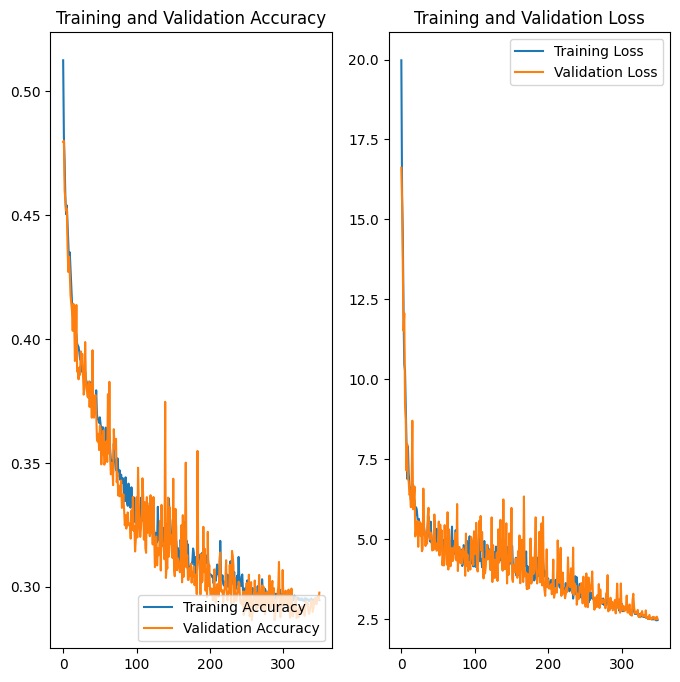

In [49]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

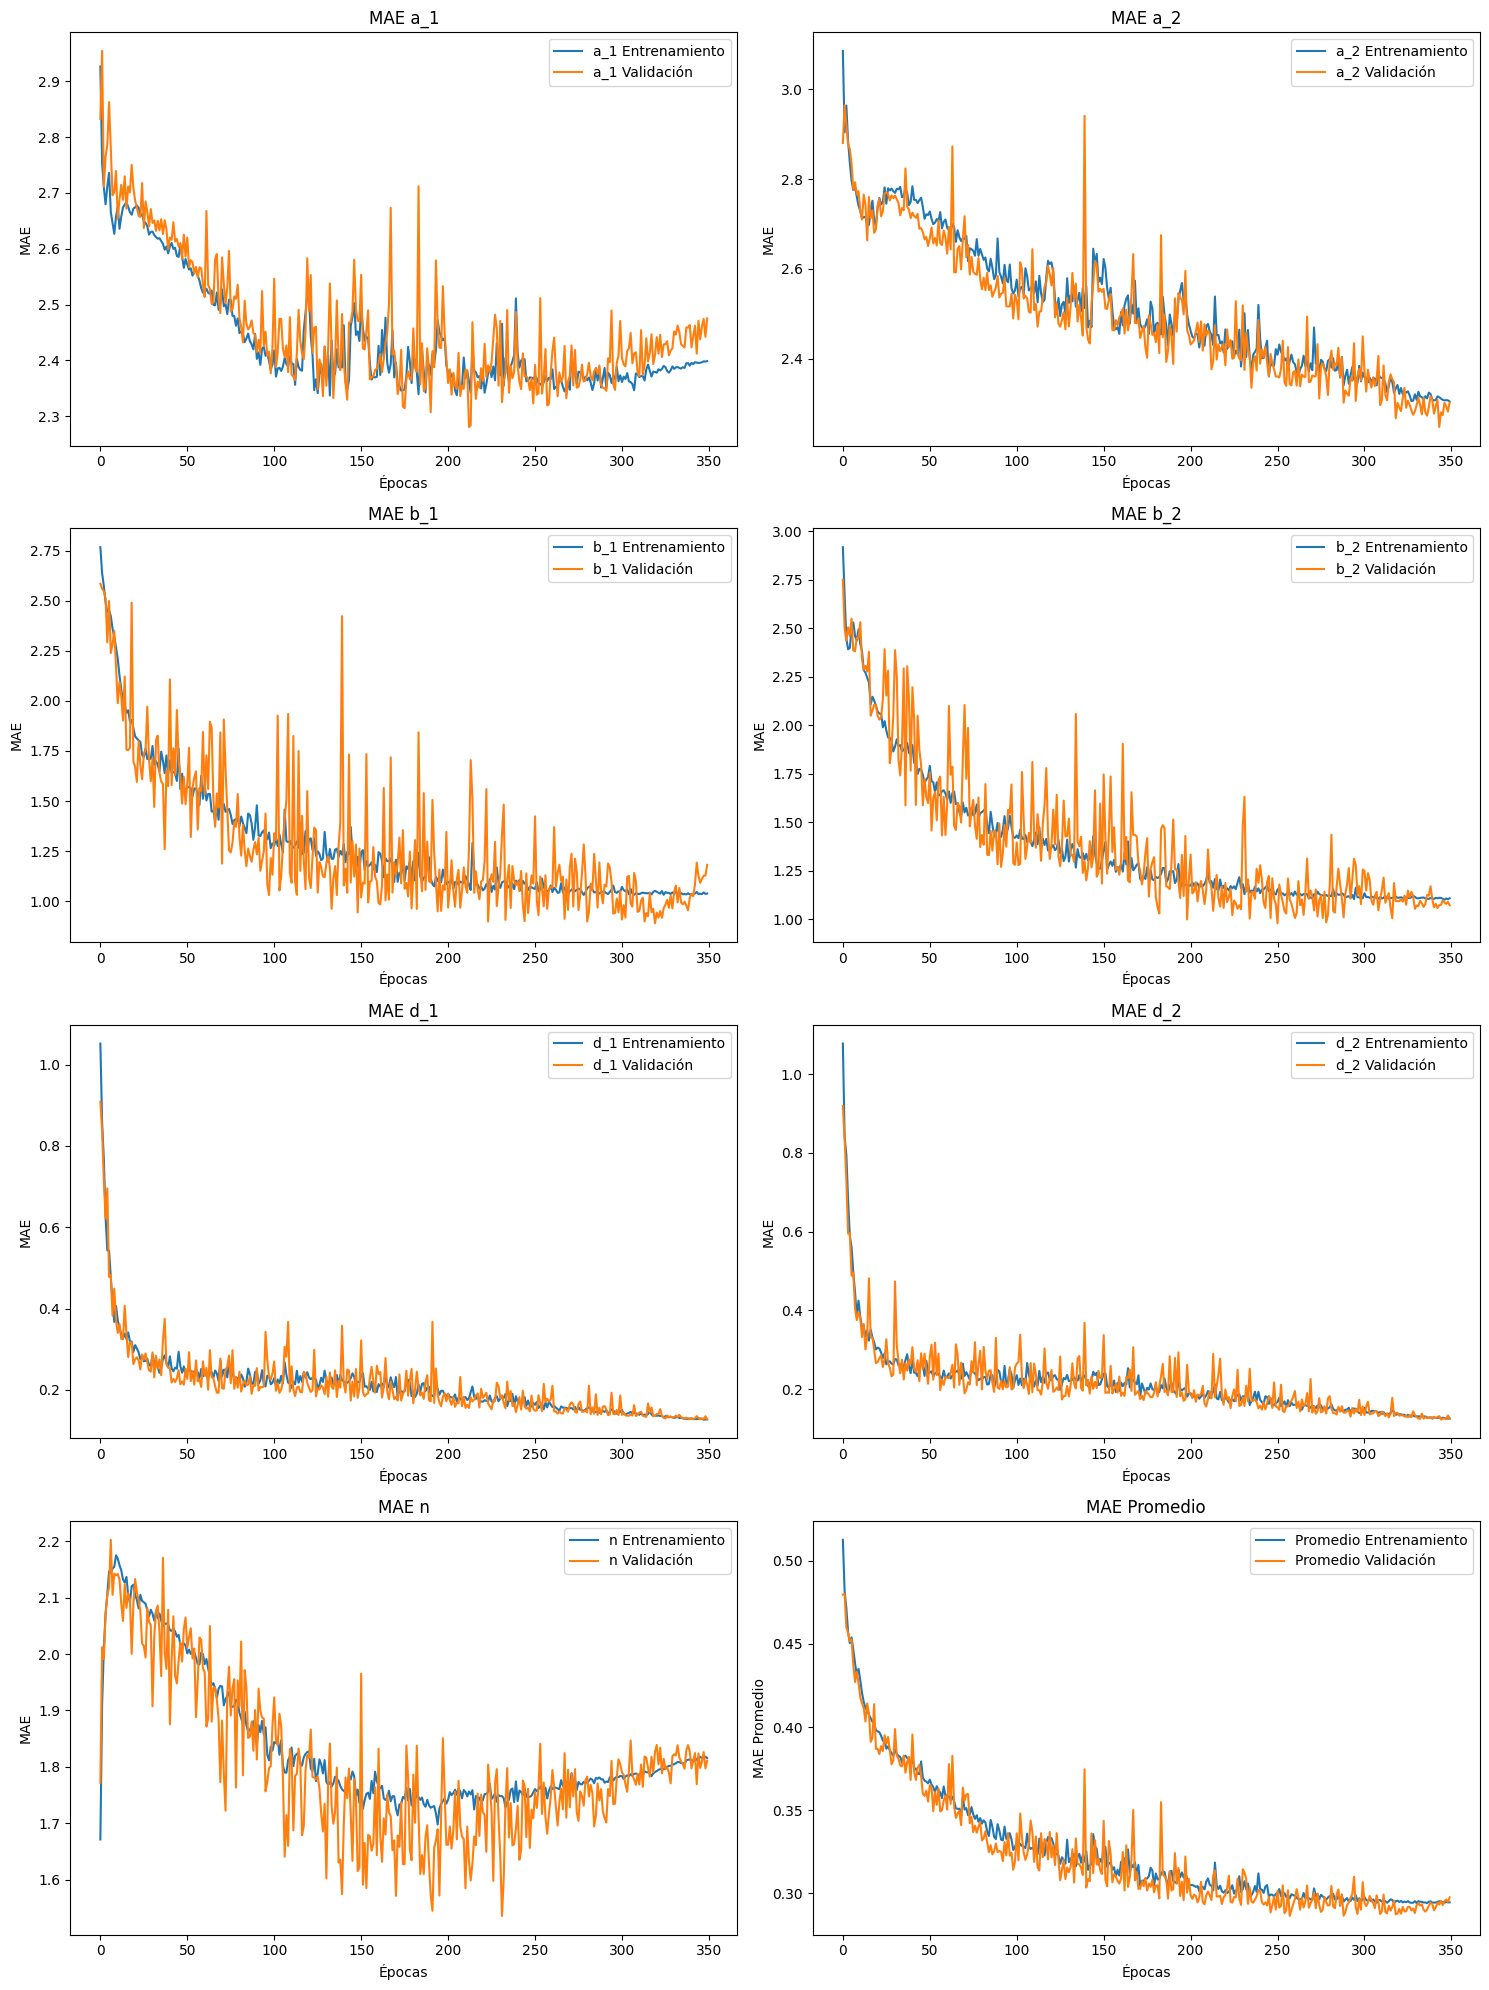

In [50]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [51]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 2ms/step - loss: 2.5405 - a_1: 2.4161 - a_2: 2.3389 - b_1: 1.1766 - b_2: 1.0524 - d_1: 0.1352 - d_2: 0.1226 - n: 1.8000 - mean_metric: 0.2957


In [52]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 739us/step


In [53]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[ 7  2 10  1 10  0  1]
[3.9011765  2.7935064  6.570245   1.3093632  9.18039    0.03698728
 0.73316276]
[31 32 28 49 25 38 26 42 31 27 24 18 37 33 38 30 24 36 37 38 36 33 20 37
 24 35 39 26 22 26 39 26 38 42 17 23 26 25 36 24 42 34 42 29 38 28 41 30
 34 35 42 16 26 28 40 28 32 40 28 35 28 38 34 32 42 39 38 29 33 38 34 30
 32 39 32 27 31 38 22 36 29 30 35 32 43 32 29 30 41 22 23 47 31 26 34 19
 29 42 30 22 33 38 25 29 36 41 34 40 32 35 40 39 31 38 21 37 43 40 30 41
 31 29 40 31 34 36 54 26 39 29 50 26 47 33 44 11 47 27 33 18 32 43 36 34
 30 34 38 46 24 32 21 48 41 44 42 40 35 29 34 31 33 28 37 30 29 38 35 33
 32 25 38 35 25 27 21 28 38 40 23 38 34 22 42 37 33 20 40 22 35 34 24 33
 37 31 35 31 28 23 36 34 40 25 30 31 34 39 26 26 37 36 45 34 28 30 39 37
 37 35 33 45 31 35 37 31 38 27 35 29 23 51 20 25 31 24 37 43 27 25 27 37
 26 36 36 39 34 23 24 44 31 30 43 41 31 32 40 28 40 32 36 24 47 44 20 28
 29 35 27 30 27 37 53 43 47 46 21 20 20 31 39 28 38 26 36 41 27 30 50 33
 34 37 27 35 23 37 39

1.2506975073899542

In [54]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 1.2882128438815208, Desviación estándar del error: 1.8478259147195333, Error absoluto máximo: 8.144452810287476


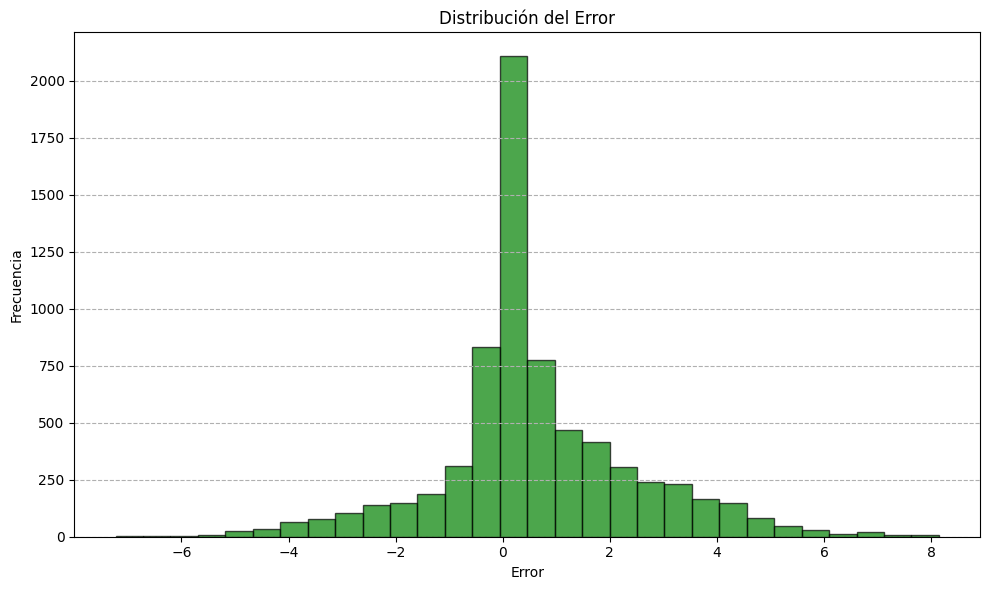

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [56]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.285649339681832
Desviación estándar del error relativo: 0.1162961246520359
Error absoluto máximo relativo: 0.7135291153734381


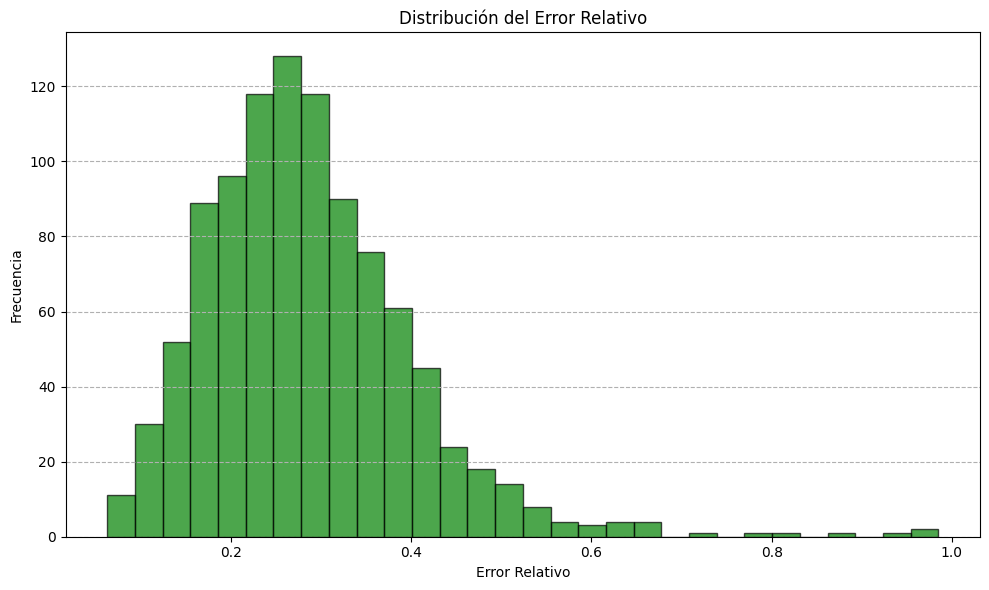

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos Accuracy y Loss

In [58]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid20_traj50/historycampvec20funcioncosto.csv', index=False)

# Guardamos el modelo

In [59]:
path_to_save = '../../../trained_models_clean/grid20_traj50'

In [60]:
model.save(path_to_save + '/campovectorial20funcioncosto.h5')

# Importamos el modelo

In [5]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [6]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [8]:
def custom_loss(y_true, y_pred):
    campvec = []
    # constantes
    a1 = tf.cast(y_true[:, 0], tf.float64)
    #tf.print(a1)
    a1 = tf.reshape(a1, shape=(-1, 1, 1))

    a2 = tf.cast(y_true[:, 1], tf.float64)
    a2 = tf.reshape(a2, shape=(-1, 1, 1))
    
    b1 = tf.cast(y_true[:, 2], tf.float64)
    b1 = tf.reshape(b1,shape = (-1,1,1))
    
    b2 = tf.cast(y_true[:, 3], tf.float64)
    b2 = tf.reshape(b2,shape = (-1,1,1))

    d1 = tf.cast(y_true[:, 4], tf.float64)
    d1 = tf.reshape(d1, shape=(-1, 1, 1))

    d2 = tf.cast(y_true[:, 5], tf.float64)
    d2 = tf.reshape(d2, shape=(-1, 1, 1))

    n = tf.cast(y_true[:, 6], tf.float64)
    n = tf.reshape(n, shape=(-1, 1, 1))

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        X = tf.cast(X, tf.float64)
        X = tf.reshape(X, shape=(1, 20,20))
        Y = y[1]
        Y = tf.cast(Y, tf.float64)
        Y = tf.reshape(Y, shape=(1, 20,20))
        
        # definimos cada ODE
        dX_dt = tf.divide(a1,(1 + tf.math.pow(Y, n)+1e-5)) - tf.multiply(d1,X) + b1
        dY_dt = tf.divide(a2,(1 + tf.math.pow(X, n)+1e-7)) - tf.multiply(d2,Y) + b2
        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 20
    y_range_neg = 0
    y_range_pos = 20
    y1 = tf.linspace(x_range_neg, x_range_pos, 20)
    y2 = tf.linspace(y_range_neg, y_range_pos, 20)
    Y1, Y2 = tf.meshgrid(y1, y2)
    t = 0
    u, v = tf.zeros(Y1.shape), tf.zeros(Y2.shape)
    u, v = f(t, [Y1, Y2])
    #M = tf.sqrt(tf.square(u) + tf.square(v))
    #u /= M
    #v /= M
# ----------------------------------------------------------------------------
    campvec2 = []
    # constantes
    a12 = tf.cast(y_pred[:, 0], tf.float64)
    a12 = tf.reshape(a12, shape=(-1, 1, 1))

    a22 = tf.cast(y_pred[:, 1], tf.float64)
    a22 = tf.reshape(a22, shape=(-1, 1, 1))
    
    b12 = tf.cast(y_pred[:, 2], tf.float64)
    b12 = tf.reshape(b12,shape = (-1,1,1))
    
    b22 = tf.cast(y_pred[:, 3], tf.float64)
    b22 = tf.reshape(b22,shape = (-1,1,1))

    d12 = tf.cast(y_pred[:, 4], tf.float64)
    d12 = tf.reshape(d12, shape=(-1, 1, 1))

    d22 = tf.cast(y_pred[:, 5], tf.float64)
    d22 = tf.reshape(d22, shape=(-1, 1, 1))

    n2 = tf.cast(y_pred[:, 6], tf.float64)
    n2 = tf.reshape(n2, shape=(-1, 1, 1))
    
    def f2(t2, ye2):

        # asignar a cada ODE a un elemento de vector
        X2 = ye2[0]
        X2 = tf.cast(X2, tf.float64)
        X2 = tf.reshape(X2, shape=(1, 20,20))
        Y2 = ye2[1]
        Y2 = tf.cast(Y2, tf.float64)
        Y2 = tf.reshape(Y2, shape=(1, 20,20))

        # definimos cada ODE
        dX2_dt = tf.divide(a12,(1 + tf.math.pow(Y2, n2)+1e-8)) - tf.multiply(d12,X2) + b12
        dY2_dt = tf.divide(a22,(1 + tf.math.pow(X2, n2)+1e-8)) - tf.multiply(d22,Y2) + b22
        return [dX2_dt, dY2_dt]

    y12 = tf.linspace(x_range_neg, x_range_pos, 20)
    y22 = tf.linspace(y_range_neg, y_range_pos, 20)
    Y12, Y22 = tf.meshgrid(y12, y22)
    u2, v2 = tf.zeros(Y12.shape), tf.zeros(Y22.shape)
    u2, v2 = f2(t, [Y12, Y22])
    #M2 = tf.sqrt(tf.square(u2) + tf.square(v2))
    #u2 /= M2
    #v2 /= M2
    campvecx = tf.abs(tf.subtract(u,u2))
    campvecy = tf.abs(tf.subtract(v,v2))
    campvec_magnitude = tf.add(campvecx,campvecy)
    loss = tf.reduce_mean(campvec_magnitude)
    #tf.print(y_pred)
    return loss

custom_objects = {'custom_activation':custom_activation, 'custom_loss': custom_loss,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)

In [9]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)

In [10]:
new_model = keras.models.load_model('../../../trained_models_clean/grid20_traj50/campovectorial20funcioncosto.h5', 
                                     custom_objects= custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [13]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 20)
    y2 = np.linspace(y_range_neg, y_range_pos, 20)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)
    contador = contador+1
    print(contador)
    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[0, 4, 6, 7, 10, 3, 0]
1


In [14]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [15]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 54ms/step
[[2. 4. 3. 7. 9. 3. 0.]]


## Encontramos puntos de equilibrio datos reales

In [16]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(0.6, 3.0000000000000004)


## Graficamos con los coeficientes reales

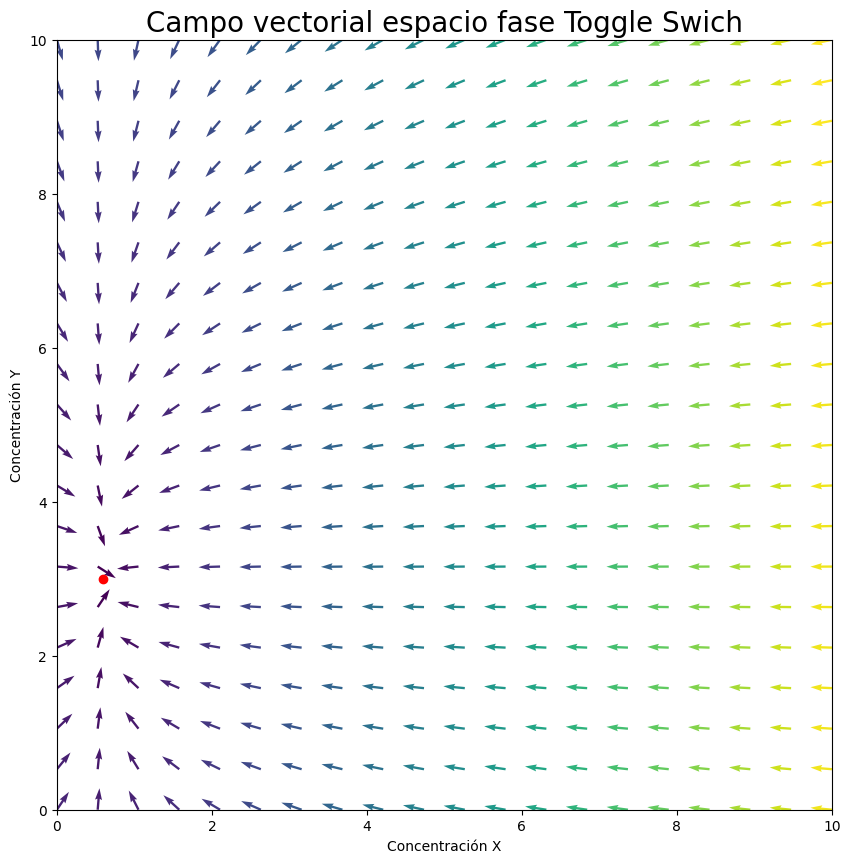

In [17]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]

y1 = np.linspace(0, 10, 20)
y2 = np.linspace(0, 10, 20)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')
plt.show()

## Encontramos puntos de equilibrio datos predecidos

In [18]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(0.4444444444444445, 3.0000000000000004)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

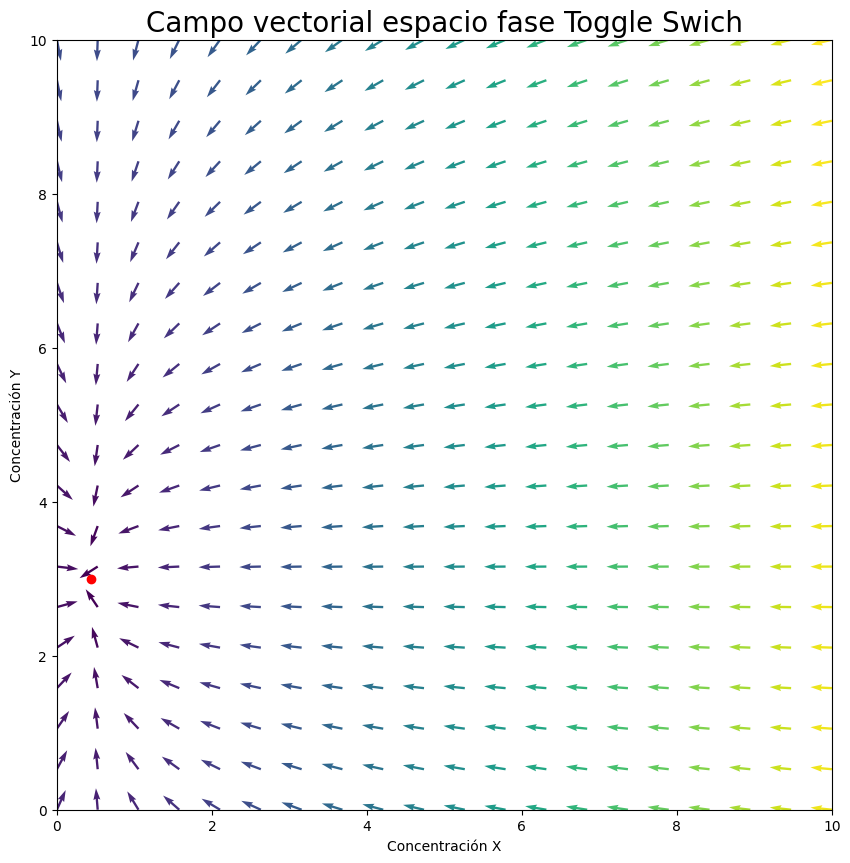

In [21]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 20)
y2pred = np.linspace(y_range_neg, y_range_pos, 20)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

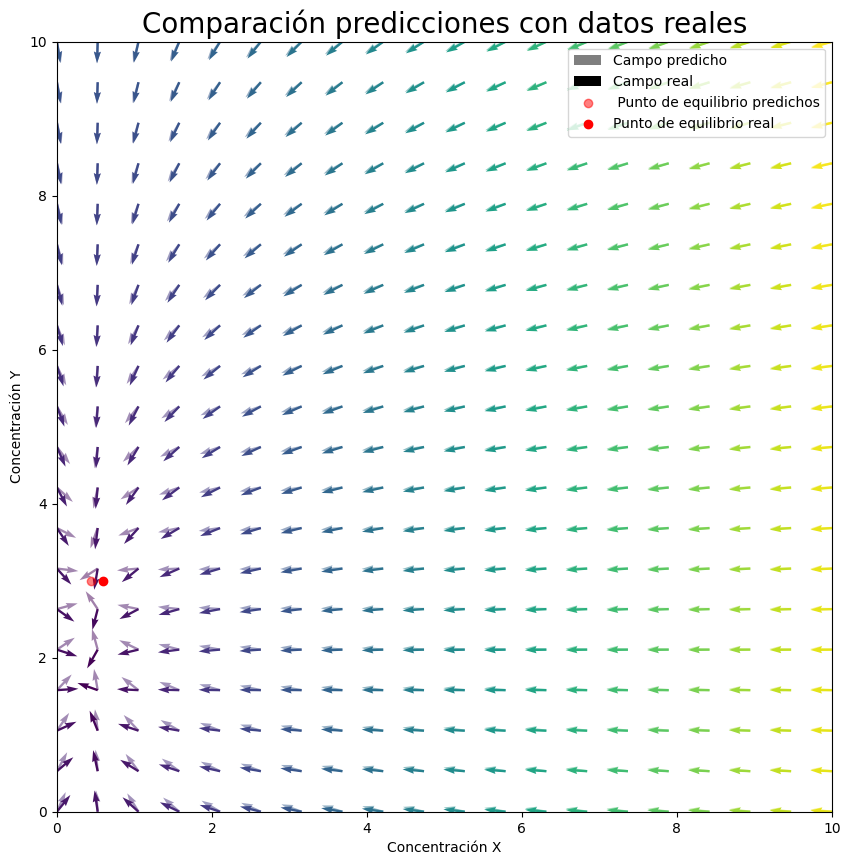

In [22]:
#%matplotlib qt
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5, label = "Campo predicho")

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1, label = "Campo real")

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5, label = " Punto de equilibrio predichos")
ax.scatter(x_values, y_values, color='red', alpha = 1, label = "Punto de equilibrio real")
ax.set_title('Comparación predicciones con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')
ax.legend(loc='upper right')  # Agregar leyenda a la gráfica
plt.show()

## Graficamos las diferencias

55.34454409574435


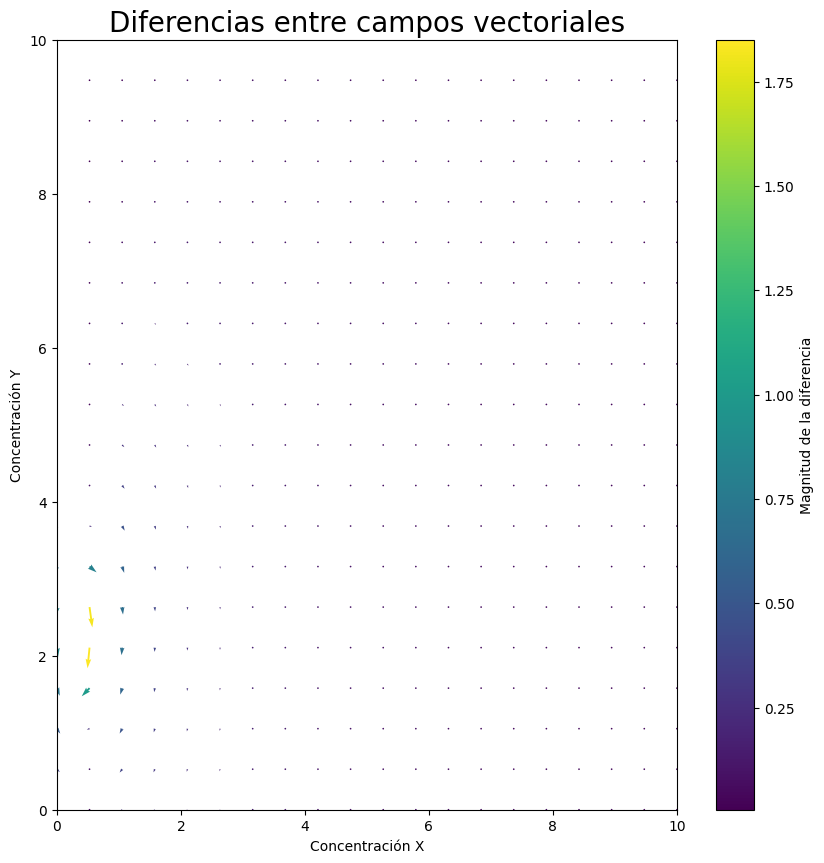

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

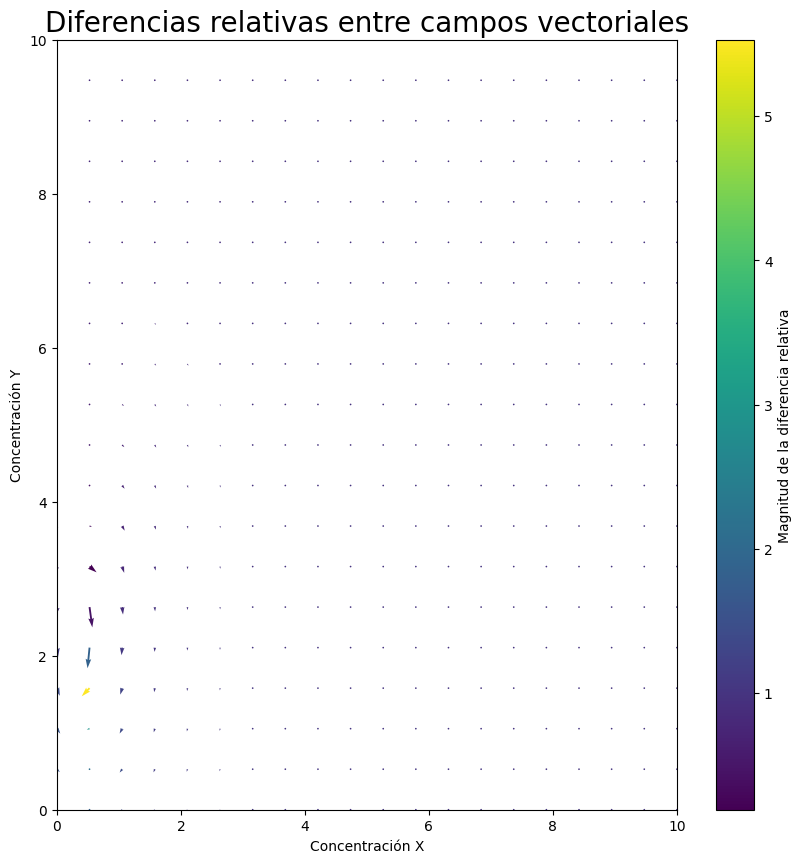

In [24]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [25]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 5.529435126495615
El valor de u1 en el error relativo máximo es: -0.7368421052631575
El valor de u1pred en el error relativo máximo es: -0.7368421052631575
El valor de v1 en el error relativo máximo es: 0.2631578947368425
El valor de v1pred en el error relativo máximo es: 4.2631578947368425


In [26]:
np.sqrt(u1pred[max_coords]**2+v1pred[max_coords]**2)/np.sqrt(u1[max_coords]**2+v1[max_coords]**2)

5.529435833200725

In [27]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 84.75%


## Simulamos n veces

In [12]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 20)
    y2 = np.linspace(y_range_neg, y_range_pos, 20)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 20)
    y2pred = np.linspace(y_range_neg, y_range_pos, 20)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

--------------------------------------------
1/1 [==============================] - 0s 33ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 16.75%
--------------------------------------------
1/1 [==============================] - 0s 65ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 14.25%
--------------------------------------------
1/1 [==============================] - 0s 77ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 3.50%
--------------------------------------------
1/1 [==============================] - 0s 36ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 84.75%
--------------------------------------------
1/1 [==============================] - 0s 76ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 6.00%
--------------------------------------------
1/1 [===========================

1/1 [==============================] - 0s 58ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 15.50%
--------------------------------------------
1/1 [==============================] - 0s 43ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 28.00%
--------------------------------------------
1/1 [==============================] - 0s 56ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 28.25%
--------------------------------------------
1/1 [==============================] - 0s 58ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 23.00%
--------------------------------------------
1/1 [==============================] - 0s 40ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 26.50%
--------------------------------------------
1/1 [==============================] - 0s 24ms/step
El porcentaje de p

1/1 [==============================] - 0s 29ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 38.75%
--------------------------------------------
1/1 [==============================] - 0s 83ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 23.25%
--------------------------------------------
1/1 [==============================] - 0s 47ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 17.75%
--------------------------------------------
1/1 [==============================] - 0s 31ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 66ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 10.00%
--------------------------------------------
1/1 [==============================] - 0s 51ms/step
El porcentaje 

1/1 [==============================] - 0s 23ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 11.75%
--------------------------------------------
1/1 [==============================] - 0s 22ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 19.25%
--------------------------------------------
1/1 [==============================] - 0s 31ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 7.50%
--------------------------------------------
1/1 [==============================] - 0s 17ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 7.50%
--------------------------------------------
1/1 [==============================] - 0s 22ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 22.00%
--------------------------------------------
1/1 [==============================] - 0s 18ms/step
El porcentaje d

1/1 [==============================] - 0s 49ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 5.00%
--------------------------------------------
1/1 [==============================] - 0s 42ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 8.50%
--------------------------------------------
1/1 [==============================] - 0s 39ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 52.25%
--------------------------------------------
1/1 [==============================] - 0s 50ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 8.00%
--------------------------------------------
1/1 [==============================] - 0s 32ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 15.00%
--------------------------------------------
1/1 [==============================] - 0s 58ms/step
El porcentaje de

1/1 [==============================] - 0s 67ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 265 es 20.00%
--------------------------------------------
1/1 [==============================] - 0s 49ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 266 es 15.00%
--------------------------------------------
1/1 [==============================] - 0s 62ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 267 es 21.75%
--------------------------------------------
1/1 [==============================] - 0s 57ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 268 es 70.25%
--------------------------------------------
1/1 [==============================] - 0s 52ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 269 es 55.25%
--------------------------------------------
1/1 [==============================] - 0s 34ms/step
El porcentaje

... (216 outputs left out)

1/1 [==============================] - 0s 54ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9805 es 45.75%
--------------------------------------------
1/1 [==============================] - 0s 23ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9806 es 6.50%
--------------------------------------------
1/1 [==============================] - 0s 59ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9807 es 8.00%
--------------------------------------------
1/1 [==============================] - 0s 38ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9808 es 55.00%
--------------------------------------------
1/1 [==============================] - 0s 61ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9809 es 89.50%
--------------------------------------------
1/1 [==============================] - 0s 49ms/step
El porcent

1/1 [==============================] - 0s 46ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9849 es 19.00%
--------------------------------------------
1/1 [==============================] - 0s 42ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9850 es 17.00%
--------------------------------------------
1/1 [==============================] - 0s 45ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9851 es 8.25%
--------------------------------------------
1/1 [==============================] - 0s 74ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9852 es 18.00%
--------------------------------------------
1/1 [==============================] - 0s 64ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9853 es 43.00%
--------------------------------------------
1/1 [==============================] - 0s 59ms/step
El porcen

1/1 [==============================] - 0s 40ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9893 es 6.50%
--------------------------------------------
1/1 [==============================] - 0s 66ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9894 es 9.75%
--------------------------------------------
1/1 [==============================] - 0s 70ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9895 es 41.25%
--------------------------------------------
1/1 [==============================] - 0s 56ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9896 es 23.50%
--------------------------------------------
1/1 [==============================] - 0s 75ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9897 es 38.00%
--------------------------------------------
1/1 [==============================] - 0s 50ms/step
El porcent

1/1 [==============================] - 0s 56ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9937 es 17.25%
--------------------------------------------
1/1 [==============================] - 0s 22ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9938 es 41.25%
--------------------------------------------
1/1 [==============================] - 0s 21ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9939 es 17.75%
--------------------------------------------
1/1 [==============================] - 0s 60ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9940 es 36.25%
--------------------------------------------
1/1 [==============================] - 0s 19ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9941 es 13.00%
--------------------------------------------
1/1 [==============================] - 0s 63ms/step
El porce

El promedio de los porcentajes es 24.47%


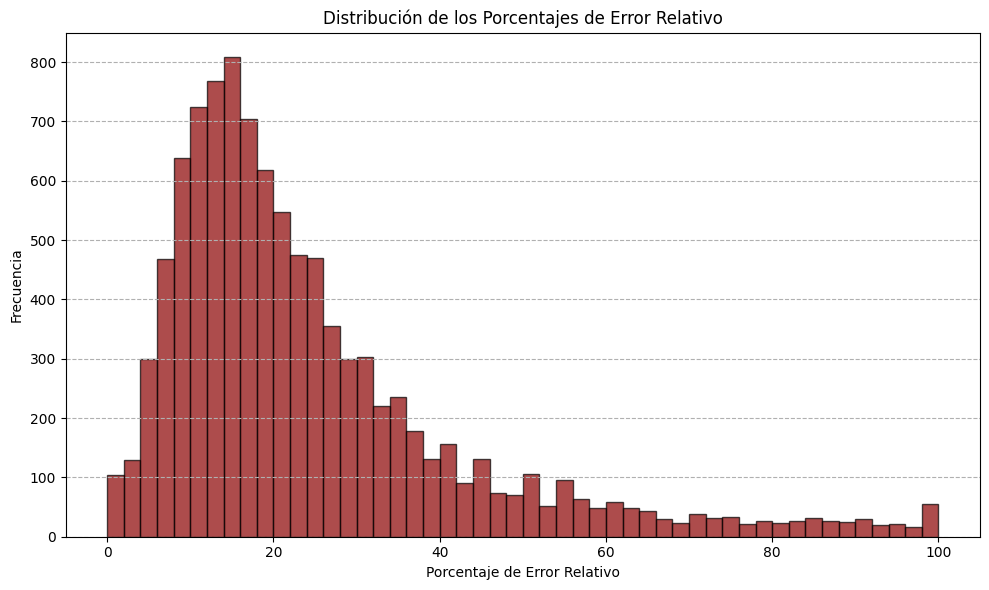

In [13]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()
